<a href="https://colab.research.google.com/github/ttobias28/PhishRadar-Project/blob/main/PhishRadar_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PhishRadar — Comparison and error analysis

**Authors:** Connor Buttrey, Oliver Conley, Robert Morriss, Ashley Smutnik, Teagan Tobias

<br>

This notebook **compares every model on the same test emails**. It does not train anything. It reads the prediction files each model notebook saved and produces:

1. one comparison table (recall, precision, F1, false-positive rate) with 95% confidence intervals,
2. a chart,
3. a significance test for whether two models really differ,
4. an error analysis (where does each model fail?),
5. the Experiment B (AI-polish) before/after comparison.

**Inputs:** every file in `MyDrive/phishradar/results/predictions/` named `<model>_<testset>.csv` (for example `tfidf_test_ceas.csv`, `distilbert_test_ceas.csv`, `llm_few_shot_test_ceas.csv`), with the columns `row_id, y_true, y_pred, score` (the LLM files also have a `status` column, which is ignored here). Models: `tfidf`, `distilbert`, `llm_zero_shot_plain`, `llm_zero_shot_detailed`, `llm_few_shot`, `llm_intent_focused`. The Experiment B ("AI polish") files in `results/b_predictions/` are read in Section 9. New models are picked up automatically: drop their files in that folder and re-run.

**Every time (Google Colab):**

1. Open this notebook in Colab (**File → Upload notebook**). No GPU is needed.
2. Make sure the split CSVs are in `MyDrive/phishradar/data/splits/`, the prediction files are in `MyDrive/phishradar/results/predictions/` and the Experiment B files are in `MyDrive/phishradar/results/b_predictions/`.
3. Run the cells top to bottom (**Runtime → Run all**) and approve the Google Drive connection.
4. Outputs are saved to `MyDrive/phishradar/results/` (table and chart) and `MyDrive/phishradar/errors/` (error files that contain email text).

**Running in plain Jupyter instead?** Use the same folder layout next to this notebook (`data/splits/`, `results/predictions/`).


## 1. Setup: connect to your files

In [1]:
from pathlib import Path

try:  # running in Google Colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/phishradar')
except ImportError:  # running locally (VS Code / Jupyter): use the current folder
    BASE = Path('.')

SPLITS = BASE / 'data' / 'splits'
PRED = BASE / 'results' / 'predictions'
RESULTS = BASE / 'results'
ERRORS = BASE / 'errors'
RESULTS.mkdir(parents=True, exist_ok=True)
ERRORS.mkdir(parents=True, exist_ok=True)
print('Predictions folder:', PRED.resolve())
print('Prediction files found:', len(list(PRED.glob('*.csv'))))

Mounted at /content/drive
Predictions folder: /content/drive/MyDrive/phishradar/results/predictions
Prediction files found: 49


## 2. Load the predictions
Each file name ends with the test set it was run on. Everything before that is treated as the model name.

In [2]:
import warnings
import numpy as np
import pandas as pd

TEST_FILES = ['test_insource', 'test_ceas', 'test_nazario', 'test_nigerian', 'test_nazario_paired']
NEEDED = {'row_id', 'y_true', 'y_pred', 'score'}

preds = {}   # (model, test set) -> DataFrame indexed by row_id
for f in sorted(PRED.glob('*.csv')):
    for t in TEST_FILES:
        if f.stem.endswith('_' + t):
            model = f.stem[:-(len(t) + 1)]
            d = pd.read_csv(f)
            if not NEEDED.issubset(d.columns):
                print('SKIPPED', f.name, '- missing columns:', sorted(NEEDED - set(d.columns)))
            else:
                preds[(model, t)] = d.set_index('row_id')
            break

assert preds, f'No prediction files found in {PRED}. Run the model notebooks first (they save <model>_<testset>.csv here).'
models = sorted({m for m, _ in preds})
print('Models found:', models)
coverage = pd.DataFrame({t: {m: (m, t) in preds for m in models} for t in TEST_FILES})
coverage

Models found: ['distilbert', 'distilbert_balanced', 'distilbert_baseline', 'distilbert_source_invariant', 'llm_few_shot', 'llm_intent_focused', 'llm_zero_shot_detailed', 'llm_zero_shot_plain', 'tfidf']


,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
distilbert,True,True,True,True,True
distilbert_balanced,True,True,True,True,True
distilbert_baseline,True,True,True,True,True
distilbert_source_invariant,True,True,True,True,True
llm_few_shot,True,True,True,True,True
llm_intent_focused,True,True,True,True,True
llm_zero_shot_detailed,True,True,True,True,True
llm_zero_shot_plain,True,True,True,True,True
tfidf,True,True,True,True,True


**Reading the table above:** `True` means that model has a prediction file for that test set. A `False` means the model has not been run on it yet (or its file is named differently). The comparison below only uses what exists.

## 3. Sanity checks
All models must agree on the true label of every row they share. If they don't, the files were built from different row orders or different splits and the comparison would be wrong.

In [3]:
for t in TEST_FILES:
    have = [m for m in models if (m, t) in preds]
    if not have:
        continue
    truth = pd.read_csv(SPLITS / f'{t}.csv', usecols=['label'])['label']
    for m in have:
        d = preds[(m, t)]
        assert d.index.isin(truth.index).all(), f'{m}/{t}: row_id outside the split file'
        assert (d['y_true'].values == truth.loc[d.index].values).all(), f'{m}/{t}: y_true does not match the split file'
    print(f'{t:<22} ok  ({", ".join(have)})')

test_insource          ok  (distilbert, distilbert_balanced, distilbert_baseline, distilbert_source_invariant, llm_few_shot, llm_intent_focused, llm_zero_shot_detailed, llm_zero_shot_plain, tfidf)
test_ceas              ok  (distilbert, distilbert_balanced, distilbert_baseline, distilbert_source_invariant, llm_few_shot, llm_intent_focused, llm_zero_shot_detailed, llm_zero_shot_plain, tfidf)
test_nazario           ok  (distilbert, distilbert_balanced, distilbert_baseline, distilbert_source_invariant, llm_few_shot, llm_intent_focused, llm_zero_shot_detailed, llm_zero_shot_plain, tfidf)
test_nigerian          ok  (distilbert, distilbert_balanced, distilbert_baseline, distilbert_source_invariant, llm_few_shot, llm_intent_focused, llm_zero_shot_detailed, llm_zero_shot_plain, tfidf)
test_nazario_paired    ok  (distilbert, distilbert_balanced, distilbert_baseline, distilbert_source_invariant, llm_few_shot, llm_intent_focused, llm_zero_shot_detailed, llm_zero_shot_plain, tfidf)


## 4. Pick the rows to score on
The LLM was run on a frozen **500-email sample** of each test set, while TF-IDF and DistilBERT ran on the **full** test sets. To compare them fairly, `SAME_ROWS = True` cuts each test set to the rows that *every* model has predictions for, so all models are scored on identical emails (`results/comparison_table.csv`). Section 5 also saves a second table with TF-IDF and DistilBERT on their **full** files (`results/comparison_table_full.csv`), which is the more precise number for those two models.

In [4]:
SAME_ROWS = True

def rows_by_model(t, same=None, only=None):
    """{model: DataFrame} for one test set. same=None uses SAME_ROWS; only = optional list of models to include."""
    same = SAME_ROWS if same is None else same
    have = [m for m in models if (m, t) in preds and (only is None or m in only)]
    if not have:
        return {}
    idx = None
    if same:
        idx = preds[(have[0], t)].index
        for m in have[1:]:
            idx = idx.intersection(preds[(m, t)].index)
    return {m: (preds[(m, t)] if idx is None else preds[(m, t)].loc[idx]) for m in have}

for t in TEST_FILES:
    r = rows_by_model(t)
    if r:
        print(f'{t:<22} {len(next(iter(r.values()))):>6} rows scored, {len(r)} model(s)')

test_insource             500 rows scored, 9 model(s)
test_ceas                 500 rows scored, 9 model(s)
test_nazario              500 rows scored, 9 model(s)
test_nigerian             500 rows scored, 9 model(s)
test_nazario_paired       500 rows scored, 9 model(s)


## 5. Metrics with 95% confidence intervals
The confidence interval comes from a **bootstrap**: resample the test emails with replacement 1,000 times, recompute each metric, and keep the middle 95%. If two models' intervals overlap a lot, the difference may be luck, especially on small samples.

Nazario and Nigerian contain **no legitimate emails**, so only recall is meaningful there (precision, F1 and false-positive rate show as NaN).

**Handling of LLM failures:** the LLM runner scores a refused/unparseable email as *predicted legitimate*, so those count against recall. This is already baked into the prediction files.

In [5]:
N_BOOT, SEED = 1000, 42
METRICS = ['recall', 'precision', 'f1', 'fpr']

def rates(y, p):
    tp = int(((y == 1) & (p == 1)).sum()); fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    has_legit = (tn + fp) > 0
    rec = tp / (tp + fn) if tp + fn else np.nan
    prec = tp / (tp + fp) if (tp + fp) and has_legit else np.nan
    f1 = 2 * prec * rec / (prec + rec) if has_legit and prec == prec and rec == rec and (prec + rec) else np.nan
    fpr = fp / (fp + tn) if has_legit else np.nan
    return np.array([rec, prec, f1, fpr])

def with_ci(y, p, rng):
    point = rates(y, p)
    n = len(y)
    boot = np.array([rates(y[i], p[i]) for i in (rng.integers(0, n, n) for _ in range(N_BOOT))])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)
    return point, lo, hi

def build_table(same, only=None):
    rng = np.random.default_rng(SEED)
    rows = []
    for t in TEST_FILES:
        for m, d in rows_by_model(t, same=same, only=only).items():
            y, p = d['y_true'].values.astype(int), d['y_pred'].values.astype(int)
            point, lo, hi = with_ci(y, p, rng)
            row = {'model': m, 'test_set': t, 'rows': len(d)}
            for k, name in enumerate(METRICS):
                row[name], row[name + '_lo'], row[name + '_hi'] = point[k], lo[k], hi[k]
            rows.append(row)
    return pd.DataFrame(rows)

table = build_table(SAME_ROWS)                       # every model on the same (LLM-sampled) rows
table.round(4).to_csv(RESULTS / 'comparison_table.csv', index=False)
FULL_MODELS = [m for m in models if not m.startswith('llm')]
table_full = build_table(False, only=FULL_MODELS)    # tfidf / distilbert on their full test sets
table_full.round(4).to_csv(RESULTS / 'comparison_table_full.csv', index=False)

def show(metric, table=table):
    t = table.copy()
    t[metric + ' (95% CI)'] = t.apply(lambda r: '' if r[metric] != r[metric] else
                                      f"{r[metric]:.3f} [{r[metric + '_lo']:.3f}, {r[metric + '_hi']:.3f}]", axis=1)
    return t.pivot(index='model', columns='test_set', values=metric + ' (95% CI)')[
        [c for c in TEST_FILES if c in set(t['test_set'])]]

print('RECALL: share of real phishing/scam caught')
display(show('recall'))
print('F1: precision and recall combined (sets with both classes only)')
display(show('f1'))
print('FALSE-POSITIVE RATE: share of legitimate emails wrongly flagged')
display(show('fpr'))

print('\n--- TF-IDF and DistilBERT on their FULL test sets ---')
for mt in ['recall', 'f1', 'fpr']:
    display(show(mt, table_full))


RECALL: share of real phishing/scam caught


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.986 [0.967, 1.000]","0.817 [0.768, 0.863]","0.814 [0.778, 0.844]","0.994 [0.986, 1.000]","0.810 [0.757, 0.855]"
distilbert_balanced,"0.986 [0.967, 1.000]","0.821 [0.772, 0.865]","0.816 [0.782, 0.850]","0.992 [0.984, 1.000]","0.829 [0.785, 0.876]"
distilbert_baseline,"0.976 [0.953, 0.995]","0.825 [0.776, 0.870]","0.832 [0.798, 0.862]","0.992 [0.984, 0.998]","0.829 [0.783, 0.873]"
distilbert_source_invariant,"0.981 [0.960, 0.996]","0.802 [0.750, 0.849]","0.792 [0.756, 0.828]","0.990 [0.980, 0.998]","0.802 [0.754, 0.849]"
llm_few_shot,"0.899 [0.858, 0.940]","0.759 [0.702, 0.807]","0.984 [0.972, 0.994]","0.998 [0.994, 1.000]","0.984 [0.969, 0.996]"
llm_intent_focused,"0.879 [0.834, 0.919]","0.759 [0.704, 0.812]","0.976 [0.962, 0.988]","0.996 [0.990, 1.000]","0.977 [0.958, 0.992]"
llm_zero_shot_detailed,"0.894 [0.850, 0.932]","0.759 [0.706, 0.810]","0.978 [0.964, 0.990]","0.998 [0.994, 1.000]","0.988 [0.974, 1.000]"
llm_zero_shot_plain,"0.918 [0.877, 0.955]","0.759 [0.705, 0.811]","0.978 [0.966, 0.990]","0.998 [0.994, 1.000]","0.988 [0.973, 1.000]"
tfidf,"0.995 [0.985, 1.000]","0.829 [0.779, 0.874]","0.780 [0.742, 0.814]","0.994 [0.986, 1.000]","0.760 [0.708, 0.810]"


F1: precision and recall combined (sets with both classes only)


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.993 [0.983, 1.000]","0.870 [0.836, 0.901]",,,"0.874 [0.839, 0.904]"
distilbert_balanced,"0.993 [0.983, 1.000]","0.867 [0.833, 0.897]",,,"0.890 [0.860, 0.918]"
distilbert_baseline,"0.988 [0.976, 0.997]","0.872 [0.836, 0.903]",,,"0.890 [0.860, 0.917]"
distilbert_source_invariant,"0.990 [0.980, 0.998]","0.858 [0.824, 0.889]",,,"0.875 [0.843, 0.905]"
llm_few_shot,"0.942 [0.916, 0.965]","0.850 [0.812, 0.882]",,,"0.988 [0.978, 0.996]"
llm_intent_focused,"0.933 [0.907, 0.956]","0.855 [0.818, 0.889]",,,"0.988 [0.979, 0.996]"
llm_zero_shot_detailed,"0.941 [0.917, 0.962]","0.850 [0.814, 0.883]",,,"0.992 [0.984, 0.998]"
llm_zero_shot_plain,"0.952 [0.930, 0.973]","0.848 [0.811, 0.881]",,,"0.990 [0.980, 0.998]"
tfidf,"0.993 [0.983, 1.000]","0.868 [0.833, 0.900]",,,"0.831 [0.794, 0.865]"


FALSE-POSITIVE RATE: share of legitimate emails wrongly flagged


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.000 [0.000, 0.000]","0.066 [0.036, 0.098]",,,"0.045 [0.020, 0.074]"
distilbert_balanced,"0.000 [0.000, 0.000]","0.078 [0.046, 0.113]",,,"0.037 [0.016, 0.064]"
distilbert_baseline,"0.000 [0.000, 0.000]","0.070 [0.040, 0.104]",,,"0.037 [0.016, 0.062]"
distilbert_source_invariant,"0.000 [0.000, 0.000]","0.070 [0.040, 0.103]",,,"0.033 [0.013, 0.058]"
llm_few_shot,"0.007 [0.000, 0.018]","0.029 [0.012, 0.051]",,,"0.008 [0.000, 0.021]"
llm_intent_focused,"0.003 [0.000, 0.011]","0.016 [0.004, 0.035]",,,"0.000 [0.000, 0.000]"
llm_zero_shot_detailed,"0.003 [0.000, 0.011]","0.029 [0.012, 0.050]",,,"0.004 [0.000, 0.013]"
llm_zero_shot_plain,"0.007 [0.000, 0.018]","0.033 [0.012, 0.058]",,,"0.008 [0.000, 0.021]"
tfidf,"0.007 [0.000, 0.017]","0.086 [0.051, 0.124]",,,"0.074 [0.045, 0.109]"



--- TF-IDF and DistilBERT on their FULL test sets ---


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.992 [0.987, 0.996]","0.854 [0.849, 0.858]","0.813 [0.793, 0.832]","0.994 [0.990, 0.996]","0.813 [0.793, 0.831]"
distilbert_balanced,"0.991 [0.985, 0.995]","0.846 [0.841, 0.851]","0.820 [0.801, 0.839]","0.994 [0.990, 0.996]","0.820 [0.800, 0.839]"
distilbert_baseline,"0.989 [0.984, 0.994]","0.857 [0.853, 0.862]","0.824 [0.806, 0.841]","0.994 [0.991, 0.997]","0.824 [0.805, 0.842]"
distilbert_source_invariant,"0.987 [0.982, 0.993]","0.844 [0.839, 0.848]","0.795 [0.774, 0.815]","0.993 [0.990, 0.996]","0.795 [0.775, 0.814]"
tfidf,"0.991 [0.986, 0.996]","0.850 [0.845, 0.855]","0.790 [0.769, 0.810]","0.994 [0.991, 0.996]","0.790 [0.771, 0.810]"


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.991 [0.987, 0.994]","0.896 [0.893, 0.899]",,,"0.865 [0.851, 0.877]"
distilbert_balanced,"0.990 [0.986, 0.993]","0.892 [0.889, 0.895]",,,"0.870 [0.857, 0.883]"
distilbert_baseline,"0.989 [0.985, 0.993]","0.899 [0.896, 0.902]",,,"0.871 [0.858, 0.883]"
distilbert_source_invariant,"0.986 [0.982, 0.990]","0.890 [0.886, 0.893]",,,"0.853 [0.839, 0.866]"
tfidf,"0.990 [0.986, 0.993]","0.884 [0.881, 0.888]",,,"0.838 [0.825, 0.852]"


test_set,test_insource,test_ceas,test_nazario,test_nigerian,test_nazario_paired
model,,,,,
distilbert,"0.008 [0.004, 0.011]","0.065 [0.061, 0.068]",,,"0.067 [0.055, 0.080]"
distilbert_balanced,"0.008 [0.004, 0.011]","0.064 [0.060, 0.067]",,,"0.065 [0.053, 0.080]"
distilbert_baseline,"0.008 [0.004, 0.012]","0.062 [0.058, 0.066]",,,"0.067 [0.056, 0.080]"
distilbert_source_invariant,"0.010 [0.007, 0.015]","0.066 [0.063, 0.070]",,,"0.069 [0.057, 0.082]"
tfidf,"0.008 [0.005, 0.013]","0.090 [0.086, 0.094]",,,"0.095 [0.081, 0.110]"


**Saved:** `results/comparison_table.csv` (all models, same rows) and `results/comparison_table_full.csv` (TF-IDF and DistilBERT on the full test sets). Numbers only, safe to commit. For the report, the key comparison is how each model's score **drops from `test_insource` to the unseen sources**.

## 6. Chart

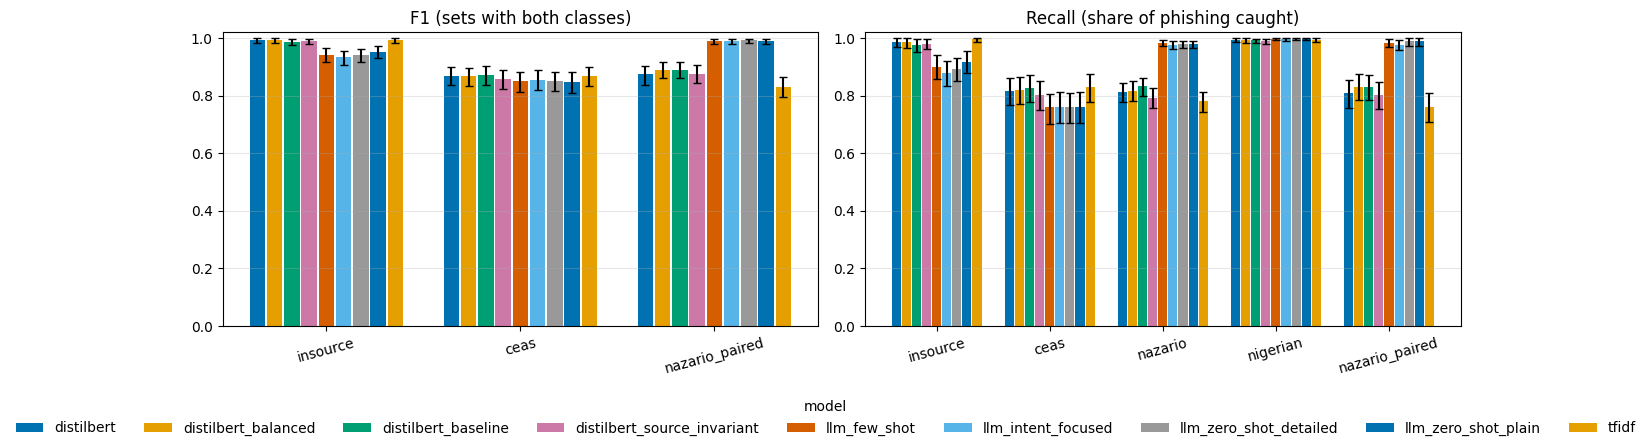

In [6]:
import matplotlib.pyplot as plt

COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00', '#56B4E9', '#999999']
panels = [('f1', 'F1 (sets with both classes)', ['test_insource', 'test_ceas', 'test_nazario_paired']),
          ('recall', 'Recall (share of phishing caught)', TEST_FILES)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, title, sets) in zip(axes, panels):
    sets = [s for s in sets if s in set(table['test_set'])]
    width = 0.8 / max(len(models), 1)
    for k, m in enumerate(models):
        sub = table[(table.model == m)].set_index('test_set')
        xs, vals, errs = [], [], []
        for j, s in enumerate(sets):
            if s in sub.index and sub.loc[s, metric] == sub.loc[s, metric]:
                xs.append(j + k * width); vals.append(sub.loc[s, metric])
                errs.append([sub.loc[s, metric] - sub.loc[s, metric + '_lo'],
                             sub.loc[s, metric + '_hi'] - sub.loc[s, metric]])
        if xs:
            ax.bar(xs, vals, width * 0.9, yerr=np.array(errs).T, capsize=3,
                   color=COLORS[k % len(COLORS)], label=m)
    ax.set_xticks([j + 0.4 - width / 2 for j in range(len(sets))])
    ax.set_xticklabels([s.replace('test_', '') for s in sets], rotation=15)
    ax.set_ylim(0, 1.02); ax.set_title(title); ax.grid(axis='y', alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='model', loc='lower center', ncol=max(len(labels), 1), frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig(RESULTS / 'comparison_chart.png', dpi=160)
plt.show()

## 7. Do two models really differ? (McNemar's test)
For each pair of models on the same rows, count the emails where **only one** of them is right. McNemar's exact test asks whether those two counts are lopsided more than chance would explain. A small p-value (under 0.05) means the difference is probably real. This is the same test to use later for the "AI polish" experiment (original vs. rewritten emails).

In [7]:
from itertools import combinations
from scipy.stats import binomtest

def mcnemar(a, b):
    ra, rb = a['y_pred'] == a['y_true'], b['y_pred'] == b['y_true']
    only_a, only_b = int((ra & ~rb).sum()), int((~ra & rb).sum())
    p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p

out = []
for t in TEST_FILES:
    r = rows_by_model(t)
    for ma, mb in combinations(sorted(r), 2):
        only_a, only_b, p = mcnemar(r[ma], r[mb])
        out.append({'test_set': t, 'model_A': ma, 'model_B': mb,
                    'only A right': only_a, 'only B right': only_b, 'p-value': round(p, 4)})
mc = pd.DataFrame(out)
mc.to_csv(RESULTS / 'mcnemar_tests.csv', index=False)
mc if len(mc) else print('Need at least two models on the same test set.')

,test_set,model_A,model_B,only A right,only B right,p-value
0,test_insource,distilbert,distilbert_balanced,2,2,1.000
1,test_insource,distilbert,distilbert_baseline,3,1,0.625
2,test_insource,distilbert,distilbert_source_invariant,2,1,1.000
3,test_insource,distilbert,llm_few_shot,22,2,0.000
4,test_insource,distilbert,llm_intent_focused,25,2,0.000
...,...,...,...,...,...,...
175,test_nazario_paired,llm_intent_focused,llm_zero_shot_plain,2,3,1.000
176,test_nazario_paired,llm_intent_focused,tfidf,78,4,0.000
177,test_nazario_paired,llm_zero_shot_detailed,llm_zero_shot_plain,1,0,1.000
178,test_nazario_paired,llm_zero_shot_detailed,tfidf,78,2,0.000


## 8. Error analysis
**No email text is printed here.** Instead we look at *what kinds* of emails each model gets wrong (short vs. long, with links, lots of capitals), and which emails several models miss together. The full error files (which do contain email text, so keep them out of GitHub) are saved to `errors/` for reading by hand.

An "error" on Nazario and Nigerian is a **miss** (real phishing labeled legitimate). On the other sets an error is a miss or a false alarm.

In [8]:
ERR_SETS = ['test_nazario', 'test_ceas']   # change to look at other test sets

def add_features(df):
    s = df['text']
    out = df.copy()
    out['length'] = pd.cut(s.str.len(), [-1, 200, 500, 1000, 3000, 10**9],
                           labels=['<200', '200-500', '500-1k', '1k-3k', '>3k'])
    out['has_url'] = s.str.contains(r'https?://|www\.', regex=True)
    out['mostly_caps'] = s.map(lambda x: sum(c.isupper() for c in x) / max(len(x), 1)) > 0.15
    return out

def error_profile(df, by):
    g = df.groupby(by, observed=True)['error']
    return pd.DataFrame({'emails': g.size(), 'errors': g.sum(), 'error rate': g.mean().round(3)})

for t in ERR_SETS:
    r = rows_by_model(t)
    if not r:
        continue
    text = add_features(pd.read_csv(SPLITS / f'{t}.csv'))
    print('=' * 70, '\n', t)
    for m, d in r.items():
        full = text.loc[d.index].assign(y_pred=d['y_pred'].values, score=d['score'].values)
        full['error'] = full['y_pred'] != full['label']
        kind = np.where(~full['error'], 'correct', np.where(full['label'] == 1, 'missed phishing', 'false alarm'))
        print(f'\n[{m}]  ', pd.Series(kind).value_counts().to_dict())
        for by in ['length', 'has_url', 'mostly_caps']:
            display(error_profile(full, by))
        full[full['error']].assign(kind=kind[full['error'].values]).to_csv(ERRORS / f'{m}_{t}_errors.csv', index=False)
print('\nError files (contain email text, do not commit) saved to', ERRORS.resolve())

 test_nazario

[distilbert]   {'correct': 407, 'missed phishing': 93}


,emails,errors,error rate
length,,,
<200,28,5,0.179
200-500,154,40,0.260
500-1k,160,29,0.181
1k-3k,138,15,0.109
>3k,20,4,0.200


,emails,errors,error rate
has_url,,,
False,423,78,0.184
True,77,15,0.195


,emails,errors,error rate
mostly_caps,,,
False,469,90,0.192
True,31,3,0.097



[distilbert_balanced]   {'correct': 408, 'missed phishing': 92}


,emails,errors,error rate
length,,,
<200,28,9,0.321
200-500,154,33,0.214
500-1k,160,29,0.181
1k-3k,138,17,0.123
>3k,20,4,0.200


... (63 outputs left out)

,emails,errors,error rate
length,,,
<200,93,2,0.022
200-500,129,2,0.016
500-1k,81,0,0.000
1k-3k,116,12,0.103
>3k,81,49,0.605


,emails,errors,error rate
has_url,,,
False,152,8,0.053
True,348,57,0.164


,emails,errors,error rate
mostly_caps,,,
False,431,21,0.049
True,69,44,0.638



Error files (contain email text, do not commit) saved to /content/drive/MyDrive/phishradar/errors


### Which emails do the models miss together?
If every model misses the same real phishing emails, those emails are genuinely hard (or mislabeled). If the models miss *different* ones, combining them could help.

In [9]:
for t in ERR_SETS:
    r = rows_by_model(t)
    if len(r) < 2:
        continue
    wrong = pd.DataFrame({m: (d['y_pred'] != d['y_true']) for m, d in r.items()})
    n_wrong = wrong.sum(axis=1)
    summary = pd.Series({'all models wrong': int((n_wrong == len(r)).sum()),
                         'some (not all) wrong': int(((n_wrong > 0) & (n_wrong < len(r))).sum()),
                         'all models right': int((n_wrong == 0).sum())})
    print(t); display(summary.to_frame('emails'))

test_nazario


,emails
all models wrong,0
some (not all) wrong,195
all models right,305


test_ceas


,emails
all models wrong,44
some (not all) wrong,55
all models right,401


## 9. Experiment B: does AI polishing change detection?
Each phishing/legitimate email was rewritten by an LLM (copy-edit only) and every model scored the **original** and the **polished** version of the same email. Only emails that were successfully rewritten are included (the rewriter refused many Nazario emails). Files: `results/b_predictions/<model>_b_orig.csv` and `<model>_b_polished.csv` with `pair_id, y_true, y_pred, score`.

For each model we report recall and false-positive rate before and after, the number of emails that flipped, and an exact McNemar test on the phishing flips (caught→missed vs. missed→caught). Note that Nigerian is near the ceiling (almost everything is caught either way) and only a few Nazario pairs survived, so this experiment has little power; a non-significant result is **not** proof of no effect.

In [10]:
BPRED = RESULTS / 'b_predictions'
bpreds = {}
for f in sorted(BPRED.glob('*_b_orig.csv')):
    model = f.stem[:-len('_b_orig')]
    fp = BPRED / f'{model}_b_polished.csv'
    if not fp.exists():
        print('SKIPPED', model, '- no polished file'); continue
    o, q = pd.read_csv(f).set_index('pair_id'), pd.read_csv(fp).set_index('pair_id')
    assert set(o.index) == set(q.index), f'{model}: pair_ids differ between orig and polished'
    q = q.loc[o.index]
    assert (o['y_true'].values == q['y_true'].values).all(), f'{model}: y_true differs between orig and polished'
    bpreds[model] = (o, q)
print('Experiment B models:', sorted(bpreds))

rows = []
for m, (o, q) in sorted(bpreds.items()):
    y = o['y_true'].values.astype(int)
    po, pp = o['y_pred'].values.astype(int), q['y_pred'].values.astype(int)
    ph, lg = y == 1, y == 0
    caught_to_missed = int((ph & (po == 1) & (pp == 0)).sum())
    missed_to_caught = int((ph & (po == 0) & (pp == 1)).sum())
    n_disc = caught_to_missed + missed_to_caught
    p = binomtest(min(caught_to_missed, missed_to_caught), n_disc, 0.5).pvalue if n_disc else 1.0
    rows.append({'model': m, 'phishing pairs': int(ph.sum()), 'legit pairs': int(lg.sum()),
                 'recall orig': po[ph].mean(), 'recall polished': pp[ph].mean(),
                 'FPR orig': po[lg].mean(), 'FPR polished': pp[lg].mean(),
                 'caught→missed': caught_to_missed, 'missed→caught': missed_to_caught,
                 'legit flips': int((lg & (po != pp)).sum()), 'McNemar p (phishing)': round(p, 4)})
b_table = pd.DataFrame(rows)
b_table.round(4).to_csv(RESULTS / 'b_comparison_table.csv', index=False)
b_table.round(4)

Experiment B models: ['distilbert', 'llm_few_shot', 'llm_intent_focused', 'llm_zero_shot_detailed', 'llm_zero_shot_plain', 'tfidf']


,model,phishing pairs,legit pairs,recall orig,recall polished,FPR orig,FPR polished,caught→missed,missed→caught,legit flips,McNemar p (phishing)
0,distilbert,176,297,0.9830,0.9830,0.0640,0.0640,0,0,6,1.0
1,llm_few_shot,176,297,0.9943,0.9886,0.0135,0.0135,1,0,2,1.0
2,llm_intent_focused,176,297,0.9943,0.9943,0.0101,0.0034,0,0,2,1.0
3,llm_zero_shot_detailed,176,297,0.9943,0.9943,0.0034,0.0034,0,0,0,1.0
4,llm_zero_shot_plain,176,297,0.9943,0.9943,0.0101,0.0135,0,0,3,1.0
5,tfidf,176,297,0.9773,0.9830,0.0842,0.0875,0,1,5,1.0


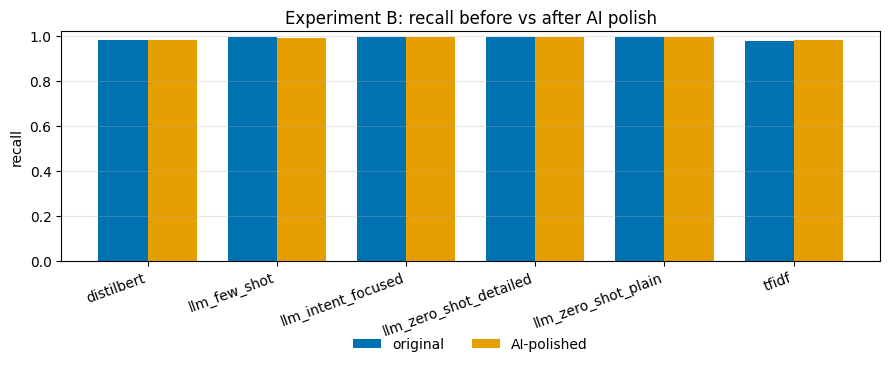

In [11]:
# Recall before vs after, per model
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(b_table)); w = 0.38
ax.bar(x - w/2, b_table['recall orig'], w, label='original', color=COLORS[0])
ax.bar(x + w/2, b_table['recall polished'], w, label='AI-polished', color=COLORS[1])
ax.set_xticks(x); ax.set_xticklabels(b_table['model'], rotation=20, ha='right')
ax.set_ylim(0, 1.02); ax.set_ylabel('recall'); ax.set_title('Experiment B: recall before vs after AI polish')
ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.tight_layout(); plt.savefig(RESULTS / 'b_chart.png', dpi=160); plt.show()

**Saved:** `results/b_comparison_table.csv` and `results/b_chart.png` (numbers only, safe to commit).